# create environment wrapper

- 128 parallel envs
- env.step(actions), returns : states, rewards, dones

- actions.shape = (n_envs, ),   discrete actions, 4
- state.shape   = (n_envs, 8),   8 dims state space for each environment
- rewards.shape = (n_envs, ),   scalar reward value, float
- dones.shape = (n_envs, ),     scaler bool value if episode done

In [1]:
import libs_common
import rl_libs 

import numpy 

n_envs = 128
envs = libs_common.VecEnv(n_envs=n_envs)


objc[54531]: Class SDLApplication is implemented in both /opt/homebrew/lib/python3.14/site-packages/envpool/gfootball/gfootball_envpool.so (0x10b525f88) and /opt/homebrew/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x11be88890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[54531]: Class SDLAppDelegate is implemented in both /opt/homebrew/lib/python3.14/site-packages/envpool/gfootball/gfootball_envpool.so (0x10b525fd8) and /opt/homebrew/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x11be888e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[54531]: Class SDLTranslatorResponder is implemented in both /opt/homebrew/lib/python3.14/site-packages/envpool/gfootball/gfootball_envpool.so (0x10b526050) and /opt/homebrew/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x11be88958). This may cause spurio

# create A2C agent 

- state   : 8 elements
- actions : 4
- tiny MLP model
- learning rate 0.002
- policy buffer steps 128
- gamma factor 0.99
- exntropy exploration 0.01

In [2]:
rl_agent = rl_libs.A2CAgent(
    n_envs=n_envs,
    state_shape=(8,),
    n_actions=4,
    Model=rl_libs.MLPRLModel,
    learning_rate=0.001,
    n_steps=128,    
    gamma=0.99, 
    entropy_beta=0.001,
    device="cpu",
)


MLPRLModel(
  (lin0): Linear(in_features=8, out_features=128, bias=True)
  (act0): SiLU()
  (lin1): Linear(in_features=128, out_features=128, bias=True)
  (act1): SiLU()
  (actor): Linear(in_features=128, out_features=4, bias=True)
  (critic): Linear(in_features=128, out_features=1, bias=True)
)
n_envs       =  128
n_steps      =  128
gamma        =  0.99
entropy_beta =  0.001
device       =  cpu


# main training loop

- obtain initial state, call reset (state, reward, done)
- init logger for episodic rewards
- run main training loop

In [ ]:

# init variables for agent
state  = envs.reset()
reward = numpy.zeros(n_envs, dtype=numpy.float32)
done   = numpy.zeros(n_envs, dtype=bool)

# logging : store accumulated rewards per episode for each env 
reward_episode_sum = numpy.zeros(n_envs) 
reward_episode     = 0.0

rewards_all_mean = []
rewards_all_std  = []


for n in range(200000):

    actions = rl_agent.step(state, reward, done, True)

    state, reward, done = envs.step(actions)

    reward_episode_sum += reward

    # several envs may finish on the same step
    for i in numpy.flatnonzero(done):
        reward_episode = reward_episode_sum[i]
        reward_episode_sum[i] = 0.0

    rewards_all_mean.append(reward_episode_sum.mean())
    rewards_all_std.append(reward_episode_sum.std())
        
    if (n % 10000) == 0:
        print(n, round(float(reward_episode), 4))


rl_agent.save("results/a2c_lunar_lander/")

0 0.0
10000 -1.2433
20000 -1.7739
30000 0.1279
40000 -0.2541
50000 0.0615
60000 0.146
70000 0.5464
80000 2.371
90000 2.5388
100000 2.6141
110000 3.0031
120000 0.1939
130000 2.3665
140000 2.6428
150000 1.0459
160000 2.2638
170000 2.6396
180000 2.8998
190000 2.589


# evaluation

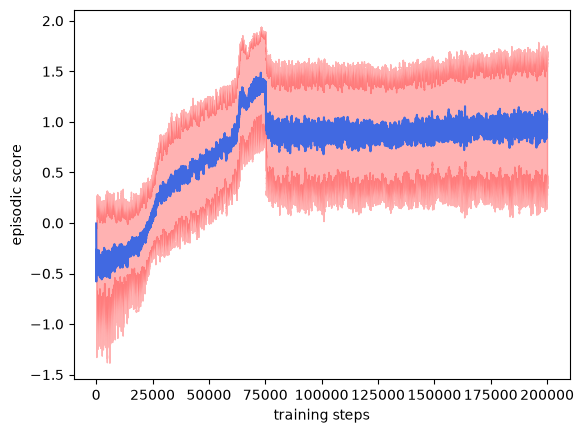

In [5]:
import matplotlib.pyplot as plt



rewards_all_mean = numpy.array(rewards_all_mean)
rewards_all_std = numpy.array(rewards_all_std)
ticks = numpy.arange(rewards_all_mean.shape[0])

plt.plot(ticks, rewards_all_mean, color="royalblue")
plt.fill_between(ticks, rewards_all_mean - rewards_all_std, rewards_all_mean + rewards_all_std  , color="red", alpha=0.3)

plt.xlabel("training steps")
plt.ylabel("episodic score")
plt.show()